# 05 Stationarity

ARIMA-type models assume that, after some differencing, a series has a stable mean and spread. So before fitting
them we test each trimmed series: does it stay around a level, follow a trend, or wander? We use two tests that ask
opposite questions, look at the autocorrelation of a few series, and see what differencing does. The answer tells
the classical models how much to difference.

## Load

In [1]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from config import ROOT, INTERIM, TABLES, FIGS, CATEGORIES, FIG_STYLE
from stationarity import check_series, adf_p

plt.rcParams.update(FIG_STYLE)
written = []
df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                for c in ["foods", "hobbies", "household"]], ignore_index=True)
df["category"] = df["item_id"].str.split("_").str[0]
series = {i: g.sort_values("date")["sales"].to_numpy() for i, g in df.groupby("item_id")}
totals = {cat: df[df["category"] == cat].groupby("date")["sales"].sum() for cat in CATEGORIES}
totals["CA_TOTAL"] = df.groupby("date")["sales"].sum()

# six example items, two per category. They are the first two of each category in the 150-item sample that
# 07a_classical_forecasting draws (seed 42); we name them here so this notebook does not depend on a later one.
EXAMPLES = ["FOODS_1_043", "FOODS_1_085", "HOBBIES_1_004", "HOBBIES_1_005", "HOUSEHOLD_1_019", "HOUSEHOLD_1_040"]
print(len(series), "products and 4 totals")

726 products and 4 totals


## ADF and KPSS together

ADF starts from "this series has a unit root" (it wanders) and rejects that when the series keeps coming back to a
level. KPSS starts from the opposite, "this series is stationary", and rejects it when it does not stay put. We run
each with a constant and with a trend, at 5%, and combine the four answers:

| Label | Rule |
|---|---|
| stationary | ADF (constant) rejects, KPSS (constant) does not |
| trend-stationary | KPSS (constant) rejects, KPSS (trend) does not, ADF (trend) rejects |
| difference-stationary | KPSS (constant) rejects and ADF (trend) does not |
| conflicting | anything else |

We also ask `ndiffs` (KPSS-based) how many ordinary differences each series needs, and `nsdiffs` (OCSB test, period
7) whether it needs a weekly seasonal difference. These run on each full series; the forecasting notebook repeats
them on the training window only. The tests on all 726 products take about three minutes.

In [2]:
st = pd.DataFrame([{"item_id": i, **check_series(y)} for i, y in series.items()])
st["category"] = st["item_id"].str.split("_").str[0]
st.to_csv(TABLES / "stationarity_items.csv", index=False)
written.append(TABLES / "stationarity_items.csv")

agg = pd.DataFrame([{"series": k, **check_series(v.to_numpy())} for k, v in totals.items()])
agg.to_csv(TABLES / "stationarity_aggregates.csv", index=False)
written.append(TABLES / "stationarity_aggregates.csv")
agg.round(4)

,series,adf_c,kpss_c,adf_ct,kpss_ct,label,d,D
0,FOODS,0.1033,0.01,0.3360,0.01,difference-stationary,1,0
1,HOBBIES,0.0333,0.01,0.0809,0.01,difference-stationary,1,0
2,HOUSEHOLD,0.2337,0.01,0.2974,0.01,difference-stationary,1,0
3,CA_TOTAL,0.1276,0.01,0.3562,0.01,difference-stationary,1,0


In [3]:
LABELS = ["stationary", "trend-stationary", "difference-stationary", "conflicting"]
rows = []
for cat in CATEGORIES + ["ALL"]:
    d = st if cat == "ALL" else st[st["category"] == cat]
    r = {"category": cat, "n_items": len(d)}
    for lab in LABELS:
        r[lab] = (d["label"] == lab).mean()
    for k in [0, 1, 2]:
        r[f"d={k}"] = (d["d"] == k).mean()
    r["D=1"] = (d["D"] == 1).mean()
    rows.append(r)
summary = pd.DataFrame(rows)
summary.to_csv(TABLES / "stationarity_summary.csv", index=False)
written.append(TABLES / "stationarity_summary.csv")
summary.round(3)

,category,n_items,stationary,trend-stationary,difference-stationary,conflicting,d=0,d=1,d=2,D=1
0,FOODS,337,0.187,0.116,0.151,0.546,0.050,0.950,0.0,0.0
1,HOBBIES,106,0.170,0.028,0.123,0.679,0.047,0.953,0.0,0.0
2,HOUSEHOLD,283,0.148,0.067,0.177,0.608,0.067,0.933,0.0,0.0
3,ALL,726,0.169,0.084,0.157,0.590,0.056,0.944,0.0,0.0


In [4]:
conf = st[st["label"] == "conflicting"]
both = ((conf["adf_c"] < 0.05) & (conf["kpss_c"] < 0.05)).mean()
print(f"{len(conf)} conflicting items; in {both:.0%} of them ADF rejects a unit root and KPSS rejects a stable level")

# what ADF alone would have said (the test we ran when scoping)
adf_only = pd.concat([pd.read_csv(INTERIM / f"{c}_adf_results.csv") for c in ["foods", "hobbies", "household"]])
print(f"ADF alone (constant, 5%) calls {adf_only['is_stationary'].mean():.1%} of the 726 stationary")

428 conflicting items; in 92% of them ADF rejects a unit root and KPSS rejects a stable level
ADF alone (constant, 5%) calls 84.8% of the 726 stationary


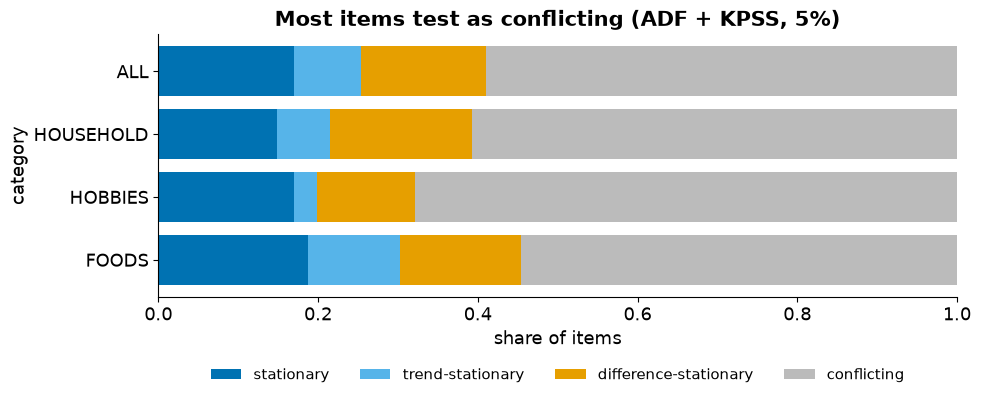

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
left = np.zeros(4)
colors = ["#0072B2", "#56B4E9", "#E69F00", "#BBBBBB"]
cats = CATEGORIES + ["ALL"]
for lab, c in zip(LABELS, colors):
    vals = summary.set_index("category").loc[cats, lab].to_numpy()
    ax.barh(cats, vals, left=left, color=c, label=lab)
    left += vals
ax.set_xlim(0, 1)
ax.set_xlabel("share of items")
ax.set_ylabel("category")
top = summary.set_index("category").loc["ALL", LABELS].idxmax()
ax.set_title(f"Most items test as {top} (ADF + KPSS, 5%)")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.38), frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "stationarity_shares.png", bbox_inches="tight")
written.append(FIGS / "stationarity_shares.png")
plt.show()

## Autocorrelation

The last two years of each series, 28 lags. Spikes at 7, 14 and 21 are the weekly pattern.

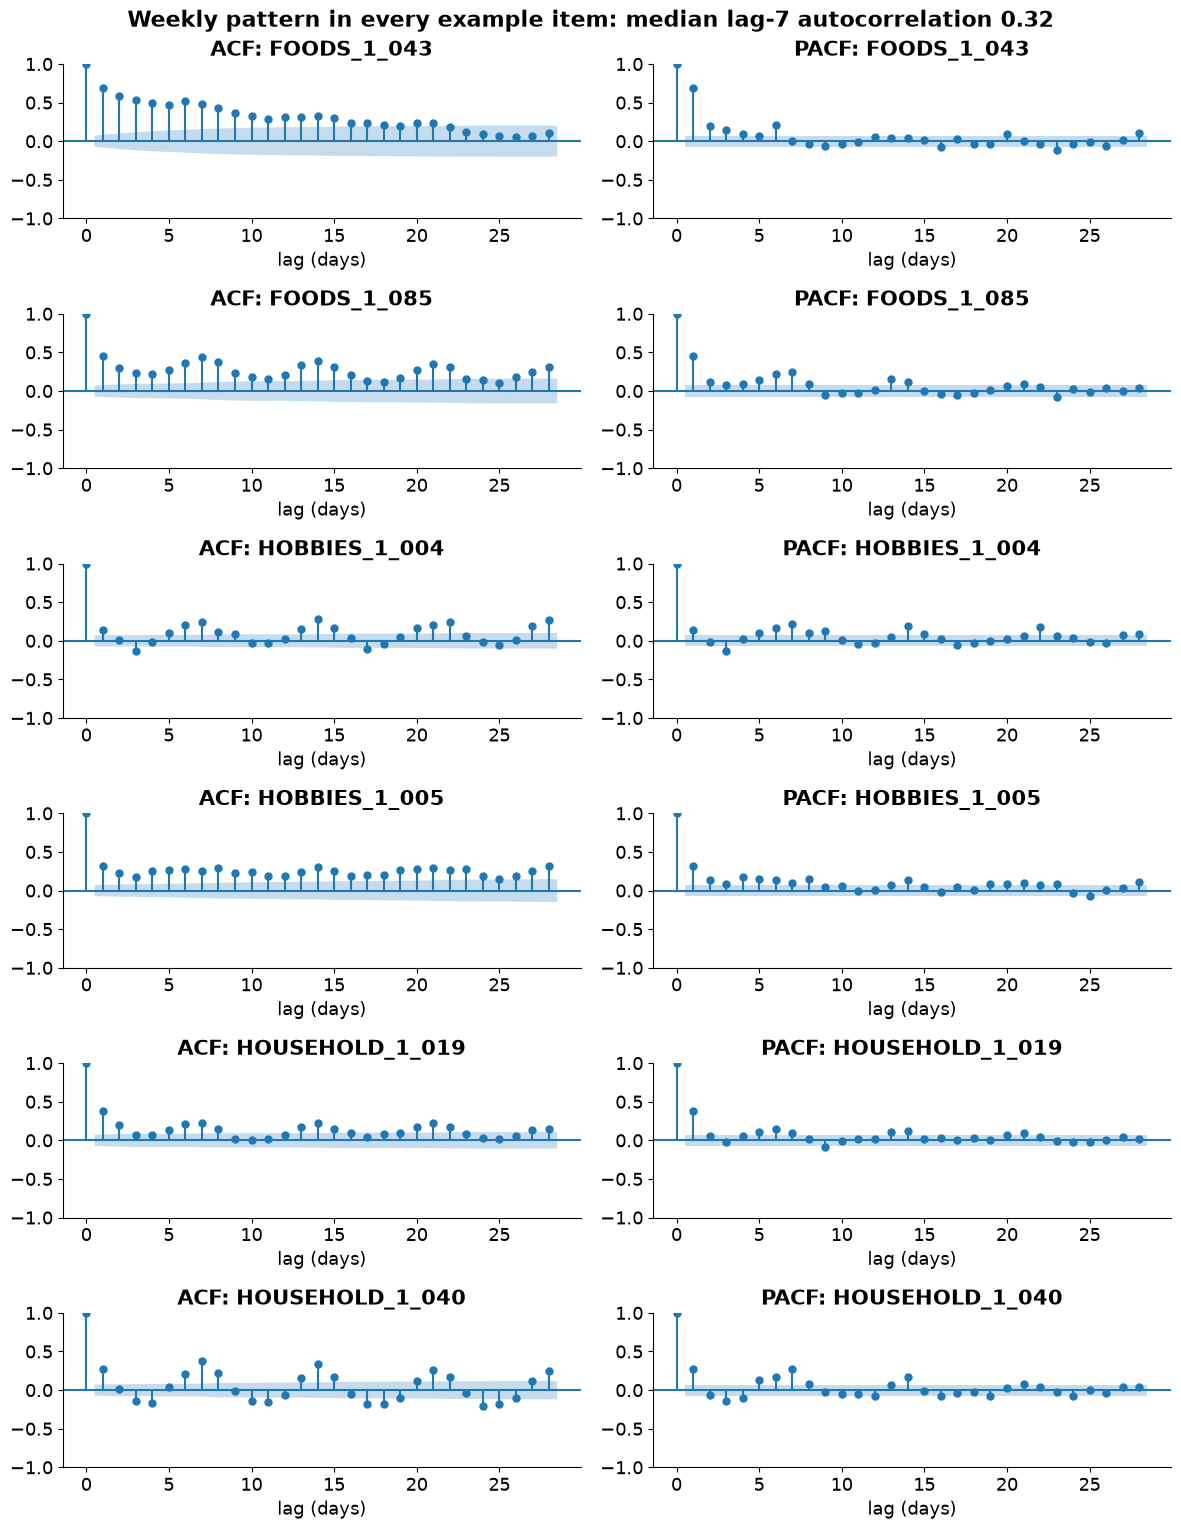

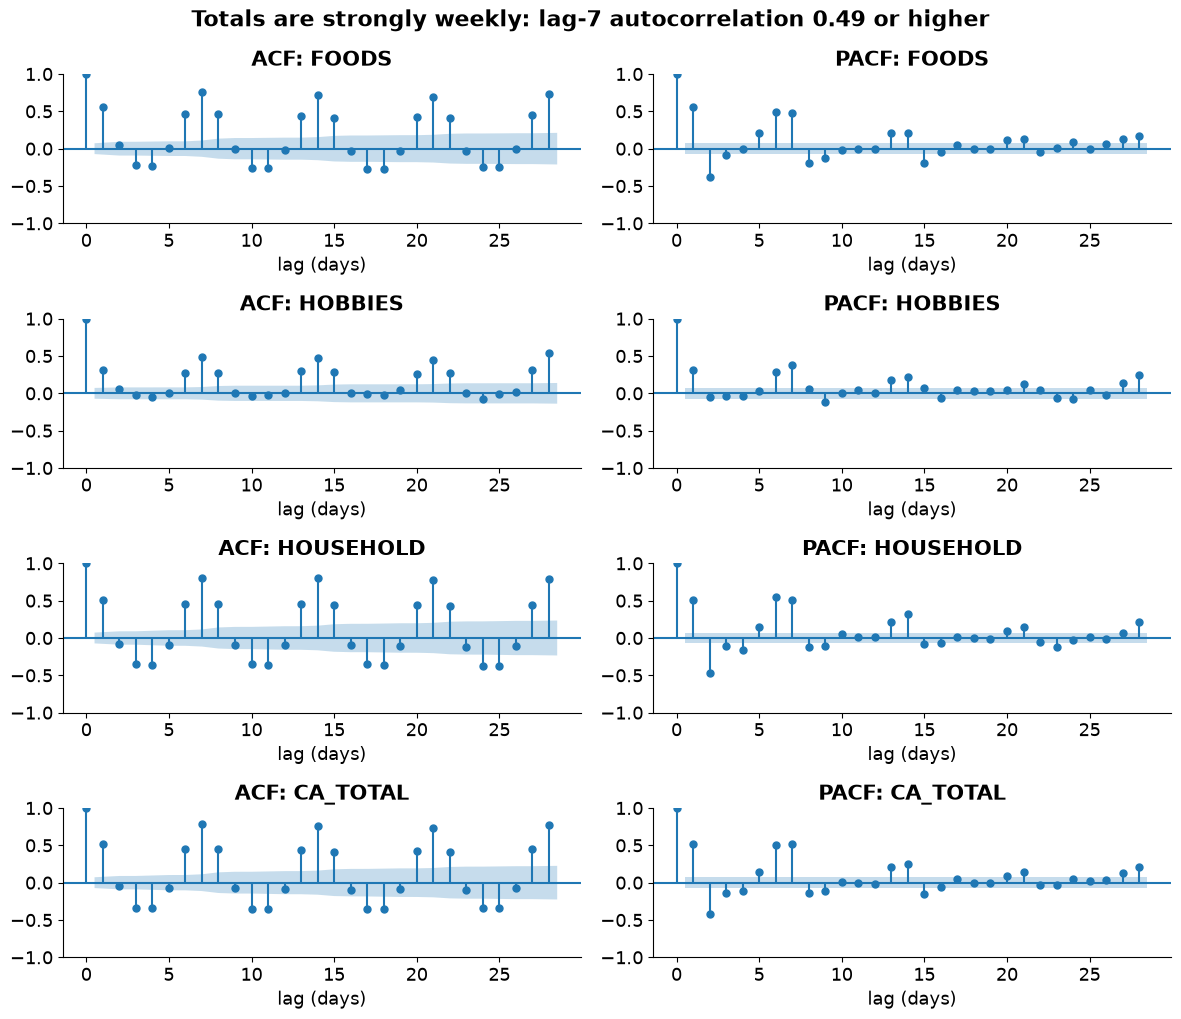

FOODS_1_043      lag 1: 0.70   lag 7: 0.48
FOODS_1_085      lag 1: 0.46   lag 7: 0.45
HOBBIES_1_004    lag 1: 0.14   lag 7: 0.25
HOBBIES_1_005    lag 1: 0.31   lag 7: 0.25
HOUSEHOLD_1_019  lag 1: 0.38   lag 7: 0.22
HOUSEHOLD_1_040  lag 1: 0.27   lag 7: 0.38
FOODS            lag 1: 0.56   lag 7: 0.77
HOBBIES          lag 1: 0.32   lag 7: 0.49
HOUSEHOLD        lag 1: 0.52   lag 7: 0.81
CA_TOTAL         lag 1: 0.51   lag 7: 0.79


In [6]:
def acf_grid(named, fname, title):
    fig, axes = plt.subplots(len(named), 2, figsize=(12, 2.6 * len(named)))
    for row, (name, y) in zip(axes, named):
        plot_acf(y, lags=28, ax=row[0], title=f"ACF: {name}")
        plot_pacf(y, lags=28, ax=row[1], title=f"PACF: {name}", method="ywm")
        row[0].set_xlabel("lag (days)")
        row[1].set_xlabel("lag (days)")
    fig.suptitle(title, fontsize=16, fontweight="bold")
    fig.tight_layout()
    fig.savefig(FIGS / fname)
    written.append(FIGS / fname)
    plt.show()

acf7 = lambda y: pd.Series(y).autocorr(7)
items = [(i, series[i][-730:]) for i in EXAMPLES]
acf_grid(items, "acf_pacf_items.png",
         f"Weekly pattern in every example item: median lag-7 autocorrelation {np.median([acf7(y) for _, y in items]):.2f}")
tots = [(k, v.to_numpy()[-730:]) for k, v in totals.items()]
acf_grid(tots, "acf_pacf_aggregates.png",
         f"Totals are strongly weekly: lag-7 autocorrelation {min(acf7(y) for _, y in tots):.2f} or higher")
for name, y in items + tots:
    print(f"{name:16s} lag 1: {pd.Series(y).autocorr(1):.2f}   lag 7: {acf7(y):.2f}")

## Before and after differencing

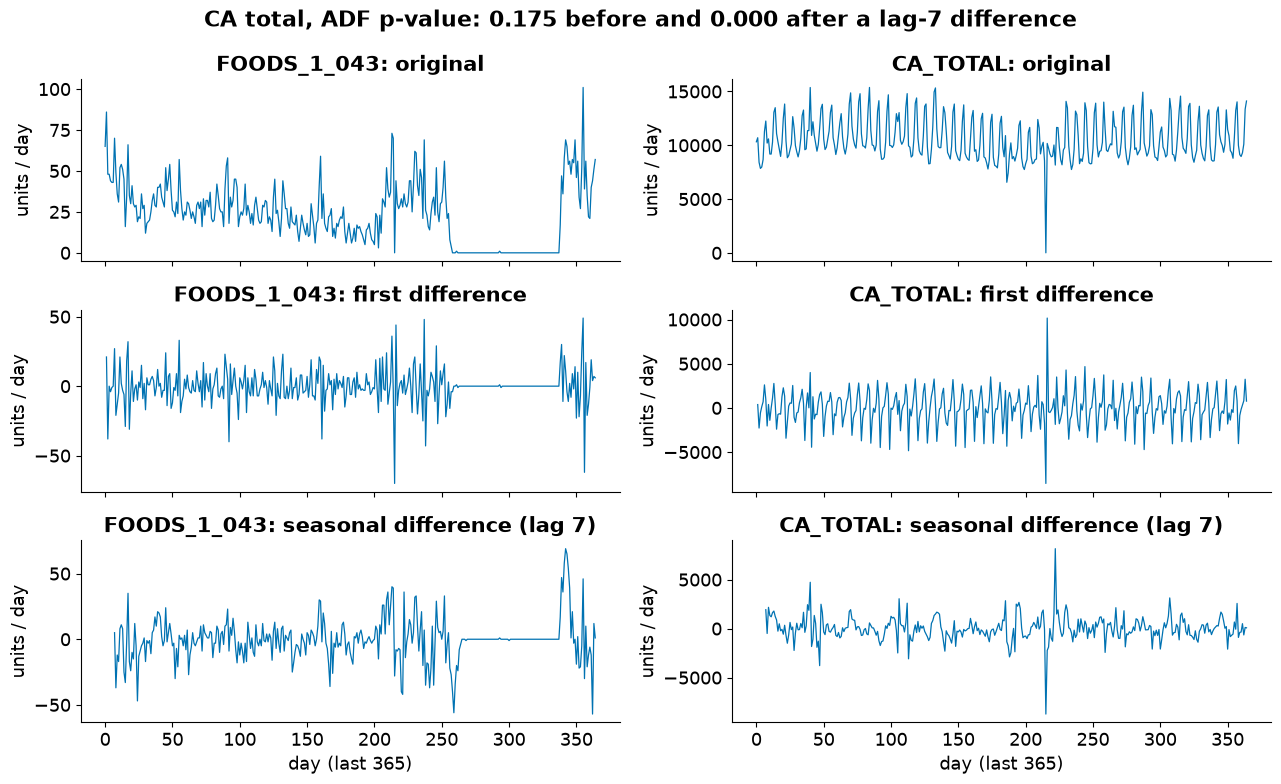

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex="col")
for col, (name, y) in enumerate([(EXAMPLES[0], pd.Series(series[EXAMPLES[0]][-365:])),
                                 ("CA_TOTAL", pd.Series(totals["CA_TOTAL"].to_numpy()[-365:]))]):
    for row, (lab, z) in enumerate([("original", y), ("first difference", y.diff()), ("seasonal difference (lag 7)", y.diff(7))]):
        axes[row, col].plot(z.to_numpy(), lw=0.9, color="#0072B2")
        axes[row, col].set_title(f"{name}: {lab}")
        axes[row, col].set_ylabel("units / day")
    axes[2, col].set_xlabel("day (last 365)")
p_before = adf_p(totals["CA_TOTAL"].to_numpy()[-365:])
p_after = adf_p(totals["CA_TOTAL"].diff(7).dropna().to_numpy()[-365:])
fig.suptitle(f"CA total, ADF p-value: {p_before:.3f} before and {p_after:.3f} after a lag-7 difference",
             fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "differencing.png")
written.append(FIGS / "differencing.png")
plt.show()

## What we found

We expected most products to be stationary, because ADF on its own said so when we scoped them (84.8% of the 726).
With KPSS alongside it the picture is less tidy: only 16.9% are cleanly stationary, 8.4% trend-stationary, 15.7%
difference-stationary, and 59.0% conflicting. In 92% of the conflicting ones both tests reject at once: ADF says the
series does not wander, and KPSS says it does not hold one level either. That is what a series looks like when it
stays around a level that shifts every now and then, which is exactly what notebook 08 goes looking for. KPSS is
also very strict on long series like these (about 1,900 days), which adds to the count.

For the models this means: `ndiffs` asks for one ordinary difference for 94% of products, and `nsdiffs` asks for no
seasonal difference for any of them. The weekly pattern is still there, as the spikes at lags 7, 14 and 21 show, so
it has to come from seasonal terms in the model rather than from differencing. All four totals test as
difference-stationary. Over the last year, a lag-7 difference takes the California total from an ADF p-value of 0.175 to below 0.001.

## What comes next

`06_decomposition` splits the series into trend, weekly season and the rest, and looks at the yearly season.

In [8]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\stationarity_items.csv 72 KB
outputs\tables\stationarity_aggregates.csv 0 KB
outputs\tables\stationarity_summary.csv 1 KB
outputs\figures\stationarity_shares.png 41 KB
outputs\figures\acf_pacf_items.png 258 KB
outputs\figures\acf_pacf_aggregates.png 171 KB
outputs\figures\differencing.png 343 KB
